In [16]:
import pandas as pd

df = pd.read_csv("../data/raw/TrainingDataset.csv")

In [17]:
df.shape

(11055, 31)

In [18]:
df.columns.tolist()

['having_IP_Address',
 'URL_Length',
 'Shortining_Service',
 'having_At_Symbol',
 'double_slash_redirecting',
 'Prefix_Suffix',
 'having_Sub_Domain',
 'SSLfinal_State',
 'Domain_registeration_length',
 'Favicon',
 'port',
 'HTTPS_token',
 'Request_URL',
 'URL_of_Anchor',
 'Links_in_tags',
 'SFH',
 'Submitting_to_email',
 'Abnormal_URL',
 'Redirect',
 'on_mouseover',
 'RightClick',
 'popUpWidnow',
 'Iframe',
 'age_of_domain',
 'DNSRecord',
 'web_traffic',
 'Page_Rank',
 'Google_Index',
 'Links_pointing_to_page',
 'Statistical_report',
 'Result']

In [19]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  int64
 14  L

In [21]:
df.isna().sum().sort_values(ascending=False)

having_IP_Address              0
Submitting_to_email            0
Statistical_report             0
Links_pointing_to_page         0
Google_Index                   0
Page_Rank                      0
web_traffic                    0
DNSRecord                      0
age_of_domain                  0
Iframe                         0
popUpWidnow                    0
RightClick                     0
on_mouseover                   0
Redirect                       0
Abnormal_URL                   0
SFH                            0
URL_Length                     0
Links_in_tags                  0
URL_of_Anchor                  0
Request_URL                    0
HTTPS_token                    0
port                           0
Favicon                        0
Domain_registeration_length    0
SSLfinal_State                 0
having_Sub_Domain              0
Prefix_Suffix                  0
double_slash_redirecting       0
having_At_Symbol               0
Shortining_Service             0
Result    

In [33]:
print(df.duplicated().sum())

5206


In [23]:
print(df["Result"].value_counts(dropna=False))

print((df["Result"].value_counts(normalize=True) * 100).round(2))

print(df["Result"].dtype)

Result
 1    6157
-1    4898
Name: count, dtype: int64
Result
 1    55.69
-1    44.31
Name: proportion, dtype: float64
int64


In [24]:
print(df.dtypes.value_counts())

print(df.nunique().sort_values().to_string())

print(df.duplicated().sum())

print(df["Result"].value_counts())

int64    31
Name: count, dtype: int64
having_IP_Address              2
Google_Index                   2
Page_Rank                      2
DNSRecord                      2
age_of_domain                  2
Iframe                         2
popUpWidnow                    2
RightClick                     2
on_mouseover                   2
Redirect                       2
Abnormal_URL                   2
Submitting_to_email            2
Statistical_report             2
Result                         2
Prefix_Suffix                  2
Request_URL                    2
HTTPS_token                    2
port                           2
Favicon                        2
Domain_registeration_length    2
Shortining_Service             2
double_slash_redirecting       2
having_At_Symbol               2
Links_pointing_to_page         3
URL_Length                     3
Links_in_tags                  3
URL_of_Anchor                  3
having_Sub_Domain              3
SSLfinal_State                 3
web_t

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Separate features and target
X = df.drop(columns="Result")
y = df["Result"].map({-1: 0, 1: 1})  # 0 = phishing, 1 = legitimate

# Stratified split preserves the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.9285,0.9234,0.9504,0.9367
SVM (RBF),0.9516,0.9418,0.9732,0.9573


In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC()
)

parameter_grid = {
    "svc__kernel": ["linear", "rbf"],
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", 0.01, 0.1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parameter_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best mean CV F1:", round(search.best_score_, 4))


Best parameters: {'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Best mean CV F1: 0.9709


              precision    recall  f1-score   support

    Phishing     0.9832    0.9571    0.9700       980
  Legitimate     0.9666    0.9870    0.9767      1231

    accuracy                         0.9738      2211
   macro avg     0.9749    0.9721    0.9733      2211
weighted avg     0.9740    0.9738    0.9737      2211



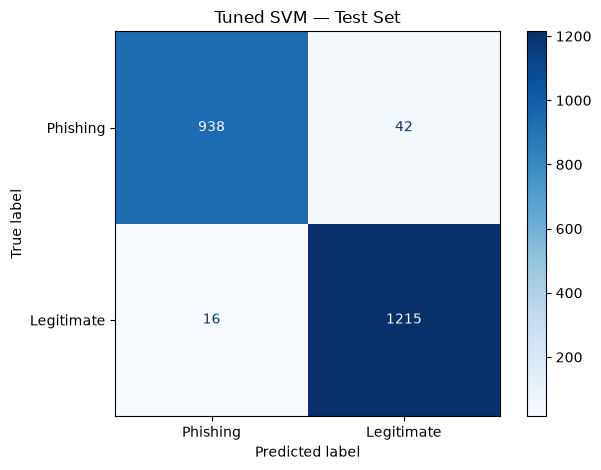

In [27]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_svm = search.best_estimator_
test_predictions = best_svm.predict(X_test)

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)

plt.title("Tuned SVM — Test Set")
plt.tight_layout()
plt.show()


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

final_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Initial RBF SVM": models["SVM (RBF)"],
    "Tuned SVM": best_svm,
}

comparison = []

for name, model in final_models.items():
    predictions = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df.round(4))


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.9285,0.9234,0.9504,0.9367
Initial RBF SVM,0.9516,0.9418,0.9732,0.9573
Tuned SVM,0.9738,0.9666,0.9870,0.9767


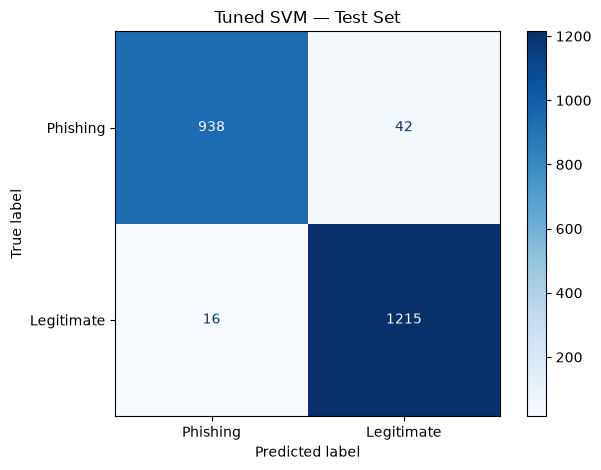

In [31]:
RESULTS_DIR = "../reports/results"
FIGURES_DIR = "../reports/figures"

comparison_df.to_csv("../reports/results/model_comparison.csv")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_svm.predict(X_test),
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)

plt.title("Tuned SVM — Test Set")
plt.tight_layout()
plt.savefig("../reports/figures/svm_confusion_matrix.png")
plt.show()